# Глава 8. Модель CatBoost и конструирование признаков

# 1. Теория

## 1.1 Идея CatBoost в прогнозировании рядов

Все прошлые модели — `NaiveModel` … `ProphetModel` — сами знали, что такое временной ряд: брали прошлые значения или функцию времени. **CatBoost** про время не знает ничего. Это градиентный бустинг над деревьями решений — обычная регрессия «таблица признаков → число». Чтобы им прогнозировать, ряд надо **превратить в таблицу**: одна строка — одна дата $\large t$, целевая переменная — $\large y_t$, признаки — то, что известно о дате $\large t$ заранее.

$$\LARGE \hat y_t = F\big(y_{t-14},\ y_{t-21},\ \ldots,\ \bar y_{t-14 \ldots t-20},\ \text{день недели}(t),\ \ldots\big)$$

где:
- $\large y_{t-k}$ — **лаг** порядка $\large k$: значение ряда $\large k$ дней назад.
- $\large \bar y_{t-14 \ldots t-20}$ — **скользящая статистика** (среднее, std, min, …) по окну прошлых значений.
- $\large \text{день недели}(t)$ — **календарный признак**: известен для любой будущей даты.
- $\large F$ — модель CatBoost, обученная на строках истории.

Вся «временная» часть живёт в признаках. Модель ровно настолько хороша, насколько хороши признаки, — поэтому глава на самом деле про **конструирование признаков**.

### Зачем лаги и скользящие статистики
Внутри CatBoost — градиентный бустинг: сотни неглубоких деревьев решений, каждое следующее исправляет ошибки предыдущих. Для нас важнее, **как модель «думает»**: на прогнозе она находит в истории строки с похожими признаками и выдаёт что-то вроде среднего их target. Что строки идут во времени подряд и что вчера похоже на сегодня, модель не знает. **Всё, что она знает о дате, — колонки её строки.** Поэтому признаки должны отвечать на вопрос: чем эта дата похожа на другие и чем отличается.

| признак | что сообщает о дате $\large t$ | чему модель может научиться |
|---|---|---|
| день недели | какой это день | недельному профилю: «в пятницу в среднем 380 заказов» |
| лаги $\large y_{t-14}, y_{t-21}, \ldots$ | сколько было в недавнем прошлом | текущему уровню: «две недели назад в пятницу было 350 — значит, и сейчас около 350» |
| скользящее среднее по `lag_14` | средний уровень за прошлые недели | тому же уровню, но без шума одного дня |
| регрессоры (праздники, акции) | что особенного в этот день | поправкам на события |

### А если без лагов и статистик?
- **Совсем без признаков** модель не запустится: `ValueError: There are not features for fitting the model!`
- **Только день недели.** Модель выучит 7 чисел — средний понедельник, средний вторник, … за всю историю — и повторит этот профиль на все 14 дней. По сути это `growth="flat"` у `ProphetModel`: недельная волна поверх константы. На ряде без тренда работает неплохо: на наших 2 юнитах `10+` такой CatBoost даёт на holdout примерно тот же SMAPE, что и с лагами (шаг 4.1). Но если уровень сместился (сезон, рост, новый юнит), модель этого не узнает: в признаках нет ничего, что говорило бы «сейчас заказов больше, чем обычно».
- **Лаги дают модели память о текущем состоянии ряда.** Она учится связи «пятница ≈ пятница две недели назад», и прогноз следует за уровнем ряда. Скользящие статистики — то же самое, только устойчивее к выбросу одного дня.
- **Номер дня как признак не поможет.** Все будущие даты больше любой даты train, поэтому для дерева они попадают в тот же лист, что и последний день истории, — прогноз будет константой. Это частный случай главного ограничения деревьев (ниже).

### Как модель прогнозирует: прямая стратегия
Прогноз на дату $\large T+h$ (где $\large T$ — последний день train, $\large h = 1 \ldots H$) — та же формула, в которую подставлены признаки этой даты. Значит, **все признаки для будущих дат должны быть известны в момент прогноза**:
- лаг $\large y_{T+h-k}$ известен, только если $\large T+h-k \le T$, то есть $\large k \ge h$. Чтобы это выполнялось для всего горизонта, **порядок лага должен быть не меньше горизонта**: $\large k \ge H$. При `HORIZON = 14` — лаги от 14 и дальше;
- календарные признаки известны всегда.

Тогда одна модель прогнозирует все 14 дней сразу, без рекурсии: свои прогнозы она в признаки не подставляет. Цена — свежую информацию модель не видит: прогноз на завтра опирается на данные двухнедельной давности, хотя есть вчерашние.

### Деревья не экстраполируют
Лист дерева хранит число — среднее остатков обучающих строк, попавших в лист. Сумма листьев всех деревьев не может уйти сильно дальше диапазона target, который модель видела в train. **Если ряд растёт, прогноз CatBoost упрётся в потолок истории.** Лечится тем, что прогнозировать надо не уровень, а приращения (`DifferencingTransform`) или ряд без тренда.

### Отличие от
- `ProphetModel` — тоже регрессия, но по одному признаку — времени, через заданную формулу $\large g(t) + s(t) + h(t)$. Тренд Prophet продолжает прямой, а CatBoost тренд не продолжает вообще. Зато CatBoost не навязывает форму зависимости: любые нелинейности и взаимодействия признаков находит сам.
- `SARIMAXModel` — тоже прогноз по прошлым значениям, но линейный и с лагами 1, 2, …: прогноз на $\large h$ шагов строится рекурсивно. CatBoost использует только лаги $\large \ge H$, зато зависимость от них любая.
- `HoltWintersModel` / `SeasonalMovingAverageModel` — сезонность у них встроена в модель. У CatBoost её надо «подать» признаками: лаги, кратные 7, или день недели.

## 1.2 Параметры и реализация

Исходник `etna/models/catboost.py`. В ETNA 3.0.0 два класса с одинаковым `__init__`:

```python
class CatBoostPerSegmentModel(
    PerSegmentModelMixin,
    NonPredictionIntervalContextIgnorantModelMixin,
    NonPredictionIntervalContextIgnorantAbstractModel,
):
    def __init__(
        self,
        iterations: Optional[int] = None,
        depth: Optional[int] = None,
        learning_rate: Optional[float] = None,
        logging_level: Optional[str] = "Silent",
        l2_leaf_reg: Optional[float] = None,
        thread_count: Optional[int] = None,
        **kwargs,
    ):

class CatBoostMultiSegmentModel(
    MultiSegmentModelMixin,
    NonPredictionIntervalContextIgnorantModelMixin,
    NonPredictionIntervalContextIgnorantAbstractModel,
):
    def __init__(...)  # те же параметры
```

Все параметры пробрасываются в `catboost.CatBoostRegressor`. `None` значит «по умолчанию CatBoost».

**Параметры:**
- `iterations` *(CatBoost: 1000)* — число деревьев.
- `depth` *(6)* — глубина дерева. CatBoost строит симметричные деревья: на каждом уровне одно условие для всех узлов, глубина $d$ — это $2^d$ листьев. Больше — сложнее взаимодействия признаков, выше риск переобучения.
- `learning_rate` *(подбирается CatBoost автоматически по размеру данных и `iterations`)* — с каким весом каждое новое дерево добавляется к сумме предыдущих. Меньше — нужно больше деревьев, но модель устойчивее.
- `l2_leaf_reg` *(3)* — L2-регуляризация значений в листьях: больше — листья ближе к нулю, модель осторожнее.
- `logging_level` *(`"Silent"`)* — ETNA глушит лог обучения CatBoost.
- `thread_count` — число потоков.
- `**kwargs` — всё остальное из `CatBoostRegressor`: `loss_function="MAE"` (по умолчанию `RMSE`), `random_seed=42` (обязательно для воспроизводимости), `random_strength`, `subsample`, …

**`PerSegment` или `MultiSegment`:**
- `CatBoostPerSegmentModel` — отдельная модель на каждый сегмент, как у всех прошлых моделей. Учится только на своём ряду.
- `CatBoostMultiSegmentModel` — **одна** модель на все сегменты: строки всех рядов складываются в одну таблицу. Данных в разы больше, модель может перенять общие закономерности (например, форму недели) от соседних рядов. Но о том, из какого ряда строка, она узнаёт только из признаков — для этого есть `SegmentEncoderTransform`.

**В отличие от `ProphetModel`:**
- признаков у модели **нет, пока их не создать**: без трансформов `fit()` падает с `ValueError: There are not features for fitting the model!`;
- модель берёт **только регрессоры** — колонки, известные в будущем (`ts.regressors`). Остальные колонки молча игнорируются (раздел 1.3);
- строки train с пропуском хотя бы в одном признаке **удаляются** перед обучением (`dropna()` в `fit` миксинов): первые `max(lags)` дней истории в обучение не попадают;
- интервалов прогноза нет (`NonPredictionInterval...`);
- `forecast(..., return_components=True)` тоже работает, но компоненты — не тренд и сезонность, а **SHAP-вклады признаков**: `target_component_lag_14`, `target_component_lag_21`, …; в сумме они дают прогноз;
- `get_model()` → `{segment: CatBoostRegressor}` у `PerSegment` и один `CatBoostRegressor` у `MultiSegment`; у него есть `feature_names_` и `get_feature_importance()`.

## 1.3 Особенности

- **`MeanTransform(in_column="target")` модель молча игнорирует.** Скользящая статистика по `target` — не регрессор: в будущем у `target` нет значений. ETNA пишет это прямо в docstring `MeanTransform`: «applied to non-regressor column, generates non-regressor column… apply this transform to target lags, not to target directly». Модель берёт только регрессоры, поэтому такой признак в обучение не попадает, и никакой ошибки нет. Правильно — статистика по лагу: `MeanTransform(in_column="lag_14", window=7)` — среднее $\large y_{t-14} \ldots y_{t-20}$.
- **И это хорошо, что игнорирует:** `MeanTransform` по `target` в строке $\large t$ включает сам $\large y_t$ — среднее окна, которое заканчивается текущим днём. В train это утечка target в признак, а в будущем окно постепенно пустеет и в последний день становится `fillna=0`.
- **Лаг меньше горизонта ETNA не запрещает.** `LagTransform(lags=[1])` даёт регрессор, модель на нём учится, а в будущем у `lag_1` значение есть только в первый день — дальше `NaN`. CatBoost пропуски не отвергает, а отправляет в отдельную ветку («меньше минимума»), и прогноз тихо портится без всякой ошибки.
- **Длинные лаги съедают историю.** Строки, где лаг ещё не определён, удаляются перед обучением. На 139 днях train с лагами до 56 модель учится на 83 строках. Годовой лаг 364 на нашем стандартном периоде с 2026-04-01 невозможен вовсе — нужна длинная история.
- **Тренд не продолжается** (раздел 1.1). На рядах с ростом или спадом — `DifferencingTransform` первым в списке трансформов: модель учится на приращениях, а `Pipeline` сам собирает уровень обратно.
- **Случайность.** Без `random_seed` два запуска дают разный прогноз. Фиксируем `random_seed=42` во всех моделях.
- **Расхождения с пособием** (там ETNA 2.x):
  - класс `CatBoostModelMultiSegment` теперь называется `CatBoostMultiSegmentModel`, `CatBoostModelPerSegment` — `CatBoostPerSegmentModel`;
  - `make_future(HORIZON, [lags, mean8])` в ETNA 3.0.0 — `make_future(future_steps=HORIZON, transforms=[...])`;
  - `MeanTransform(in_column="target", ...)` из пособия в ETNA 3.0.0 в модель не попадает (см. выше): сравнение «старого и нового способа скользящих средних» в пособии теряет смысл, рабочий только «старый» — по лагу;
  - `backtest` возвращает словарь, а не кортеж (как в тетради про `ProphetModel`).
- **Дальше:** `AutoRegressivePipeline` позволяет использовать лаг 1 — прогнозирует по шагу и подставляет свои прогнозы в лаги, как `SARIMAXModel`. А `ElasticPerSegmentModel` / `ElasticMultiSegmentModel` — та же схема «признаки → регрессия», только с линейной моделью вместо деревьев.

## 1.4 Признаки в ETNA и отбор признаков

Признаки создают **трансформы** из `etna.transforms`. Их передают списком в `Pipeline(model, transforms=[...], horizon)` — и на каждом фолде `backtest` они обучаются заново, без подглядывания в тест. Вручную то же самое — `ts.fit_transform(transforms)` на train и `ts.make_future(future_steps=HORIZON, transforms=transforms)` для будущего.

```python
LagTransform(in_column: str, lags: Union[List[int], int], out_column: Optional[str] = None)

MeanTransform(
    in_column: str,
    window: int,
    seasonality: int = 1,
    alpha: float = 1,
    min_periods: int = 1,
    fillna: float = 0,
    out_column: Optional[str] = None,
)
```

- `LagTransform` — колонки `{out_column}_{k}` для каждого `k` из `lags`. Число вместо списка `lags=5` означает лаги 1…5.
- `MeanTransform` — среднее по окну `window` значений колонки `in_column`. `seasonality=7` — среднее по тем же дням недели: $\large y_{t}, y_{t-7}, y_{t-14}, \ldots$; `alpha < 1` — экспоненциальные веса, свежие точки важнее; `min_periods` — сколько значений нужно, чтобы посчитать, иначе `fillna`.
- То же семейство: `StdTransform`, `MinTransform`, `MaxTransform`, `MedianTransform`, `MADTransform`, `QuantileTransform`. В пособии отмечено, что бустингу обычно больше всего дают среднее, std и MAD.
- `DateFlagsTransform(day_number_in_week=True, ...)` — календарные признаки (день недели, день месяца, выходной, …). Регрессоры по определению: дата будущего известна. Колонки категориальные, CatBoost обрабатывает их как `cat_features`.
- `SegmentEncoderTransform()` — категориальная колонка `segment_code` с номером сегмента. Нужна `CatBoostMultiSegmentModel`, чтобы различать ряды.
- `DifferencingTransform(in_column="target", period=1, inplace=True)` — заменяет target приращениями $\large y_t - y_{t-p}$; при прогнозе `Pipeline` собирает уровень обратно.

**Отбор признаков — тоже гиперпараметр.** Набор признаков подбирают так же, как `depth` или `learning_rate`: по ошибке на данных, которых модель не видела. В пособии — два способа:
- **валидационная выборка:** train → valid (14 дней) → test (14 дней). Подбираем на valid, тест трогаем один раз в конце;
- **backtest на train** — оценка по нескольким окнам. Надёжнее, медленнее (тетрадь про `ProphetModel` показала, насколько одно окно может обмануть).

Подсказку, какие признаки полезны, дают **важности**: `model.get_model()[segment].get_feature_importance(prettified=True)` у обученного CatBoost или `plot_feature_relevance(ts, relevance_table=ModelRelevanceTable(), relevance_params=dict(model=RandomForestRegressor()))` из `etna.analysis` — важности по отдельной модели случайного леса.

# 2. Данные

Те же файлы, что и в предыдущих тетрадях (`local/data/`, в `.gitignore`):
- `units.csv` — 10 юнитов; для основной практики берём 2 из них (размер `10+`, typical + busier), для бонуса — все 10.
- `facts-by-date.csv` — дневные факты, 2022-01-01…2026-08-31.

Период и сплит — как в прошлых тетрадях: с 2026-04-01, test — последние 14 дней (2026-08-18 … 2026-08-31). Тогда результаты сравнимы с `NaiveModel` … `ProphetModel` напрямую, в том числе в MLflow.

**Длинная история — только для эксперимента.** 2024 год в выгрузке — нули по всем юнитам, а с 2025-01-01 у обоих юнитов `10+` ряд непрерывный (608 дней, 1–2 нулевых дня). Для CatBoost длина истории важнее, чем для прошлых моделей: длинные лаги съедают начало train (раздел 1.3). Поэтому в шаге 4.2 сравним стандартный период с историей с 2025-01-01. В бонусе остаёмся на стандартном периоде: у трёх юнитов из 10 в 2025 году сотни нулевых дней (юниты ещё не открылись).

В этой главе не сравниваем с продовым прогнозом (`forecasts-by-date.csv`) — это отдельная тема, которой займёшься сам.

In [1]:
import logging
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

from etna.datasets import TSDataset
from etna.models import (
    CatBoostPerSegmentModel,
    CatBoostMultiSegmentModel,
    ProphetModel,
    HoltWintersModel,
)
from etna.transforms import (
    LagTransform,
    MeanTransform,
    DateFlagsTransform,
    DifferencingTransform,
    SegmentEncoderTransform,
)
from etna.pipeline import Pipeline
from etna.metrics import SMAPE, WAPE, MAPE, MAE
from etna.analysis import plot_forecast, plot_backtest, plot_feature_relevance, ModelRelevanceTable

from src.custom_logger import log_to_mlflow
from src.prod_metrics import bias, pooled

# Prophet здесь только для сравнения — глушим его лог cmdstanpy
logging.getLogger("cmdstanpy").disabled = True
warnings.filterwarnings("ignore", category=FutureWarning)

DATA_DIR = "../../local/data"
HORIZON = 14
RANDOM_SEED = 42

/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 3. Практика

От простого к сложному: на синтетике смотрим главное ограничение деревьев — тренд — и разбираем, какие признаки модель на самом деле видит. Потом — 2 реальных юнита: наборы признаков, длина истории, гиперпараметры на валидации и проверка через backtest. В бонусе — все 10 юнитов, `PerSegment` против `MultiSegment` и логирование в MLflow.

## Задание 1. Синтетика: деревья не экстраполируют

Смотрим, что CatBoost делает с трендом, и сравниваем с `ProphetModel`, которая тренд продолжает прямой. Синтетику удобно генерировать функцией с параметром наклона — пригодится в шагах 1.4 и в Задании 2.

### Шаг 1.1. Синтетический ряд с трендом

Собери синтетический ряд на 18 недель (126 дней), как в тетради про `ProphetModel`, но без излома: **линейный тренд** +2 в день от уровня 100, плюс недельный паттерн `[10, 20, 15, 25, 30, 50, 60]` и шум со стандартным отклонением 3 (`seed=42`). Оберни в `TSDataset` с одним сегментом `"synthetic"`.

Сделай генератор функцией с параметром `slope` — в шаге 1.4 понадобится ряд без тренда.

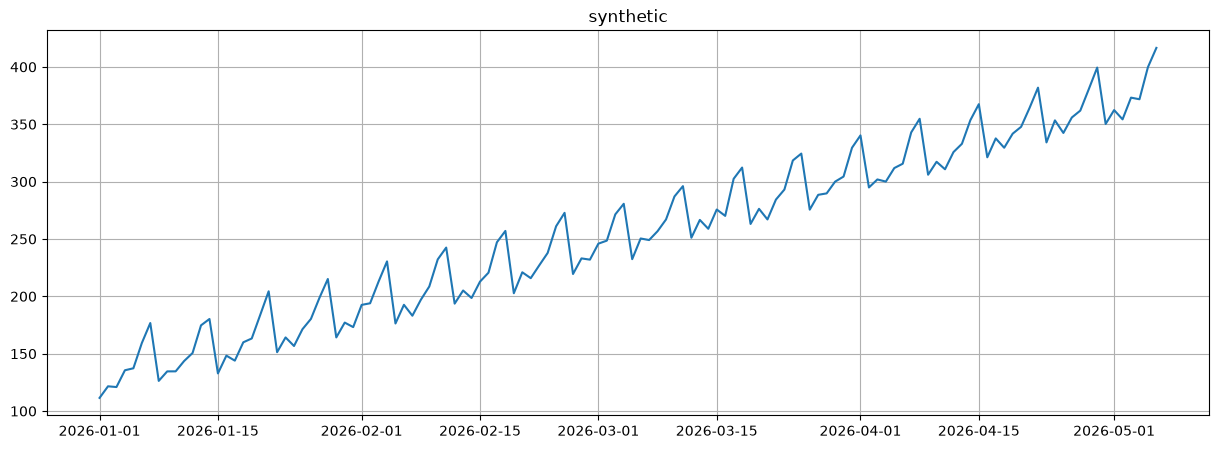

In [2]:
# Шаг 1.1. Генератор синтетики: линейный тренд + недельная сезонность + шум
DAY_OF_WEEK_PATTERN = np.array([10, 20, 15, 25, 30, 50, 60], dtype=float)


def make_trend_series(
    slope: float = 2,           # наклон тренда, заказов в день; 0 — ряд без тренда
    periods: int = 126,         # длина ряда: 18 недель
    start_level: float = 100,
    noise_sd: float = 3,
    seed: int = 42,
) -> TSDataset:
    rng = np.random.RandomState(seed)
    t = np.arange(periods)

    trend = start_level + slope * t
    seasonal = np.tile(DAY_OF_WEEK_PATTERN, periods // 7 + 1)[:periods]
    noise = rng.normal(0, noise_sd, periods)

    df = pd.DataFrame({
        "timestamp": pd.date_range("2026-01-01", periods=periods, freq="D"),
        "segment": "synthetic",
        "target": trend + seasonal + noise,
    })
    return TSDataset(df=df, freq="D")


ts = make_trend_series()  # тренд +2 в день
ts.plot(figsize=(15, 5));

#### Выводы

### Шаг 1.2. CatBoost против Prophet

Раздели на train / test (последние `HORIZON` дней). Обучи два конвейера:
- `Pipeline(CatBoostPerSegmentModel(random_seed=RANDOM_SEED), transforms=[LagTransform(in_column="target", lags=[14, 21, 28], out_column="lag")], horizon=HORIZON)`;
- `Pipeline(ProphetModel(), transforms=[], horizon=HORIZON)`.

Нарисуй оба прогноза на одном графике и посчитай SMAPE.

- Сравни максимум прогноза CatBoost с максимумом target в train и в test. Что видно?
- Почему так получилось? Вспомни раздел 1.1: что хранится в листьях дерева?

In [3]:
train_ts, test_ts = ts.train_test_split(test_size=HORIZON)

In [6]:
catboost_pipeline = Pipeline(
    CatBoostPerSegmentModel(random_seed=RANDOM_SEED),
    transforms=[
        LagTransform(in_column="target", lags=[14,21,28], out_column="lag")
    ],
    horizon=HORIZON
)

In [8]:
prophet_pipeline = Pipeline(
    ProphetModel(),
    transforms=[],
    horizon=HORIZON
)

In [9]:
forecasts = {}
for name, pipeline in {"catboost": catboost_pipeline, "prophet": prophet_pipeline}.items():
    pipeline.fit(train_ts)                 # трансформы применяются внутри, к копии
    forecasts[name] = pipeline.forecast()  # прогноз на HORIZON дней после train

errors = pd.Series({
    name: SMAPE()(y_true=test_ts, y_pred=forecast)["synthetic"]
    for name, forecast in forecasts.items()
}, name="smape").round(2)

catboost    2.12
prophet     0.84
Name: smape, dtype: float64


train_max                381.9
test_max                 416.6
catboost_forecast_max    381.4
prophet_forecast_max     409.7
dtype: float64

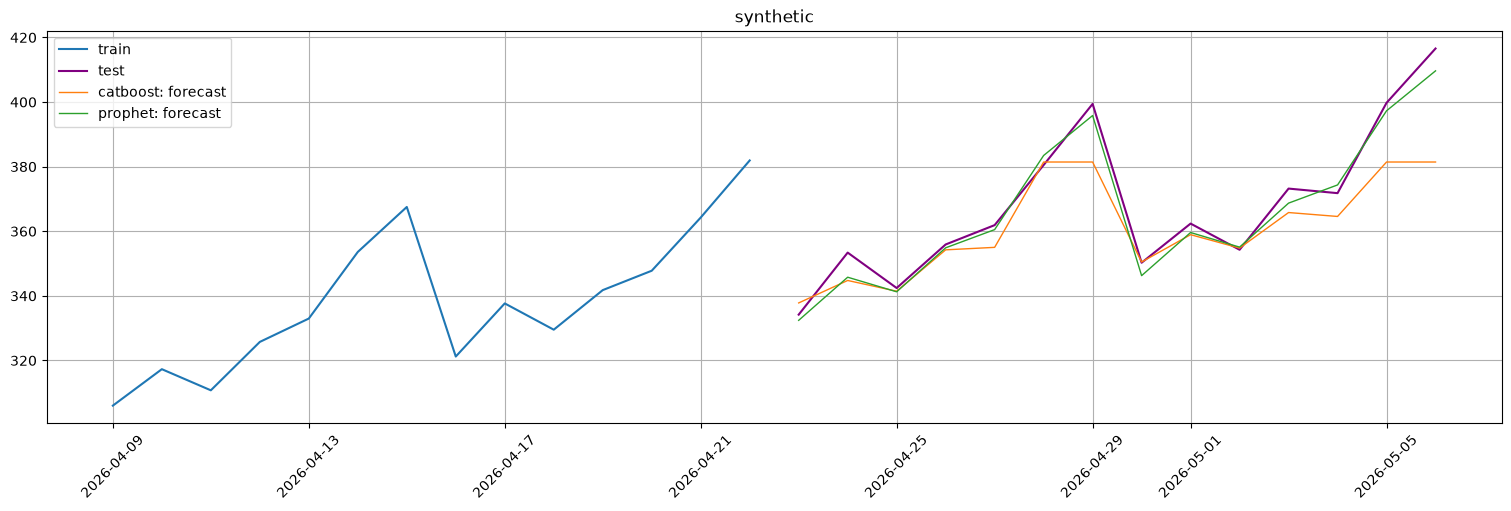

In [15]:
print(errors)

plot_forecast(forecast_ts=forecasts, test_ts=test_ts, train_ts=train_ts, n_train_samples=14, figsize=(15, 5))

pd.Series({
    "train_max": train_ts[:, "synthetic", "target"].max(),
    "test_max": test_ts[:, "synthetic", "target"].max(),
    **{f"{name}_forecast_max": forecast[:, "synthetic", "target"].max() for name, forecast in forecasts.items()},
}).round(1)

In [28]:
train_y = train_ts[:, "synthetic", "target"]
test_y = test_ts[:, "synthetic", "target"]
catboost_y = forecasts["catboost"][:, "synthetic", "target"]
prophet_y = forecasts["prophet"][:, "synthetic", "target"]
print(
    f"train_y.max(): {train_y.max()}\n",
    f"test_y.max(): {test_y.max()}\n",
    f"catboost_y.max(): {catboost_y.max()}\n",
    f"prophet_y.max(): {prophet_y.max()}\n"

)

compare_df = pd.DataFrame({
    "fact": test_y,
    "catboost": catboost_y,
    "prophet": prophet_y,
})
compare_df["catboost_error"] = compare_df["catboost"] - compare_df["fact"]
compare_df["prophet_error"] = compare_df["prophet"] - compare_df["fact"]
compare_df = compare_df[["fact", "catboost", "catboost_error", "prophet", "prophet_error"]]
compare_df.round(1)



train_y.max(): 381.92045837365237
 test_y.max(): 416.5713668774299
 catboost_y.max(): 381.43453561631515
 prophet_y.max(): 409.65734237566846



,fact,catboost,catboost_error,prophet,prophet_error
timestamp,,,,,
2026-04-23,334.2,337.8,3.6,332.4,-1.8
2026-04-24,353.4,344.8,-8.6,345.8,-7.6
2026-04-25,342.4,341.4,-1.0,341.3,-1.2
2026-04-26,355.9,354.2,-1.7,354.9,-1.0
2026-04-27,361.9,355.0,-6.9,360.5,-1.4
2026-04-28,380.5,381.4,0.9,383.5,3.0
2026-04-29,399.4,381.4,-18.0,395.8,-3.6
2026-04-30,350.3,350.5,0.2,346.3,-4.0
2026-05-01,362.4,358.9,-3.4,359.6,-2.8


#### Выводы

- **Прогноз CatBoost упирается в потолок train.** Максимум прогноза 381.4 — почти ровно максимум train (381.9), хотя в тесте ряд дорастает до 416.6. Prophet за потолок выходит (409.7): он продолжает прямую тренда.
- **Потолок — это не один день, а плато.** В 4 из 14 дней CatBoost выдаёт одно и то же число 381.4. Это вторники и среды, самые сильные дни недели (+50 и +60 к тренду). В первый вторник (04-28) факт 380.5 ещё ниже потолка, и ошибка всего 0.9. В остальные три дня факт выше всего, что модель видела в train, и ошибка растёт вместе с трендом: −18.0 в первую среду (04-29), −18.3 и −35.1 во второй вторник и среду (05-05, 05-06). В остальные дни факт лежит внутри диапазона train, и CatBoost ошибается не сильнее Prophet (в пределах ±9).
- **SMAPE 2.12 против 0.84 — в 2.5 раза хуже,** и почти весь проигрыш дают эти 4 дня. На более длинном горизонте за потолок уйдут все дни недели, и прогноз превратится в почти постоянную линию.

**Почему так.** Дерево делит строки train по условиям вида `lag_14 > 352`, а в каждом листе хранит среднее target (точнее, остатков) обучающих строк, попавших в этот лист. Прогноз — сумма листьев всех деревьев, поэтому он не может уйти дальше значений, которые модель видела в train. Когда лаги в будущем больше всех лагов train, каждое дерево отправляет строку в свой «самый правый» лист — тот же, куда попадали максимальные строки train. Отсюда одинаковые 381.4: для модели все эти дни — «как самый большой день, что я видела». Связь «лаг вырос на 30 → target вырос на 30» модель не учит, она учит только «большой лаг → большой target из истории». Prophet же — формула $g(t) + s(t)$ с прямой тренда, и прямая продолжается за пределы истории сама.

### Шаг 1.3. Прогнозируем приращения

Добавь в начало списка трансформов `DifferencingTransform(in_column="target", period=..., inplace=True)` и повтори CatBoost с `period=1` и с `period=7`. Лаги оставь те же.

- Вышел ли прогноз за потолок train? Как изменился SMAPE относительно шага 1.2 и относительно Prophet?
- Какой `period` сработал лучше и почему? Подумай, что остаётся в приращениях $y_t - y_{t-1}$ и в $y_t - y_{t-7}$ на ряде «тренд + недельный паттерн».

In [29]:
# CatBoost на приращениях: DifferencingTransform первым — дальше лаги считаются уже от приращений,
# а при прогнозе Pipeline сам собирает уровень обратно (inverse_transform)
def make_diff_pipeline(period: int) -> Pipeline:
    return Pipeline(
        CatBoostPerSegmentModel(random_seed=RANDOM_SEED),
        transforms=[
            DifferencingTransform(in_column="target", period=period, inplace=True),
            LagTransform(in_column="target", lags=[14, 21, 28], out_column="lag"),
        ],
        horizon=HORIZON,
    )


# Прогнозы из шага 1.2 (catboost, prophet) + два новых варианта
for period in [1, 7]:
    pipeline = make_diff_pipeline(period)
    pipeline.fit(train_ts)
    forecasts[f"catboost_diff_{period}"] = pipeline.forecast()

errors = pd.Series({
    name: SMAPE()(y_true=test_ts, y_pred=forecast)["synthetic"]
    for name, forecast in forecasts.items()
}, name="smape").round(2)
print(errors)

catboost           2.12
prophet            0.84
catboost_diff_1    1.95
catboost_diff_7    0.94
Name: smape, dtype: float64


train_max                       381.9
test_max                        416.6
catboost_forecast_max           381.4
prophet_forecast_max            409.7
catboost_diff_1_forecast_max    427.9
catboost_diff_7_forecast_max    408.3
dtype: float64

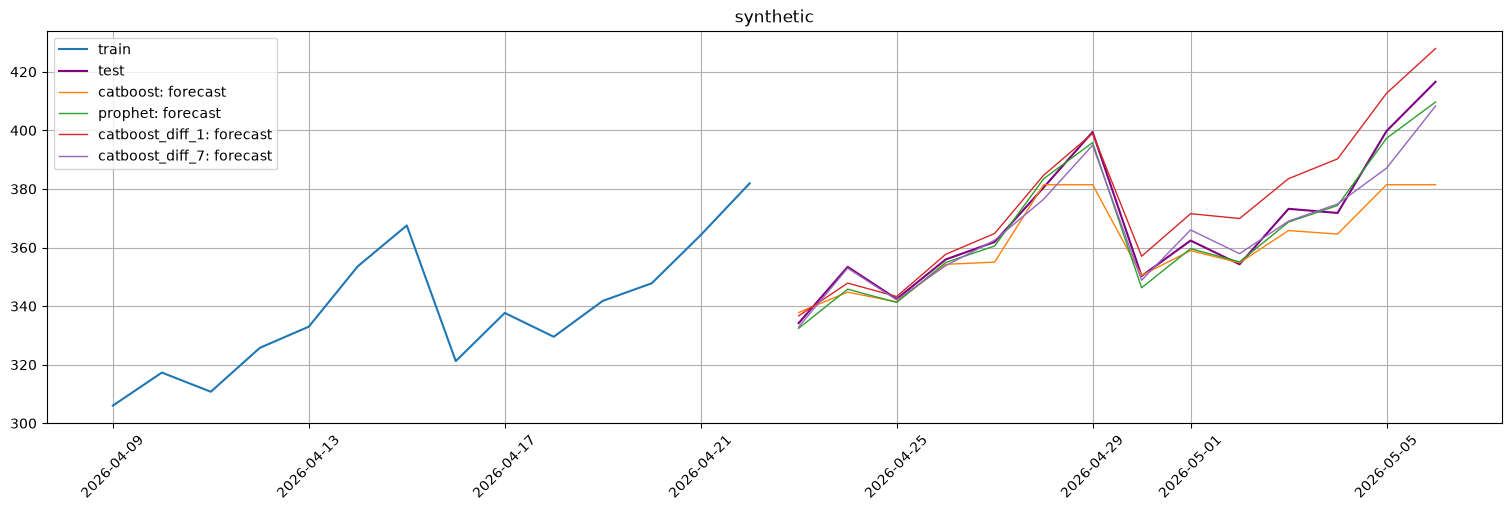

In [30]:
plot_forecast(forecast_ts=forecasts, test_ts=test_ts, train_ts=train_ts, n_train_samples=14, figsize=(15, 5))

# Вышел ли прогноз за потолок train
pd.Series({
    "train_max": train_ts[:, "synthetic", "target"].max(),
    "test_max": test_ts[:, "synthetic", "target"].max(),
    **{f"{name}_forecast_max": forecast[:, "synthetic", "target"].max() for name, forecast in forecasts.items()},
}).round(1)

In [35]:
# Ошибка по дням теста: факт и прогноз − факт для каждой модели
compare_diff_df = pd.DataFrame({"fact": test_ts[:, "synthetic", "target"]})
for name, forecast in forecasts.items():
    compare_diff_df[f"{name}_error"] = forecast[:, "synthetic", "target"] - compare_diff_df["fact"]
compare_diff_df["day_of_week"] = compare_diff_df.index.day_name()
compare_diff_df = compare_diff_df[["day_of_week", "fact", "prophet_error", "catboost_error", "catboost_diff_1_error", "catboost_diff_7_error"]]
compare_diff_df.round(1)

,day_of_week,fact,prophet_error,catboost_error,catboost_diff_1_error,catboost_diff_7_error
timestamp,,,,,,
2026-04-23,Thursday,334.2,-1.8,3.6,2.5,-1.3
2026-04-24,Friday,353.4,-7.6,-8.6,-5.5,-0.4
2026-04-25,Saturday,342.4,-1.2,-1.0,0.8,-0.3
2026-04-26,Sunday,355.9,-1.0,-1.7,1.8,-2.1
2026-04-27,Monday,361.9,-1.4,-6.9,2.9,0.6
2026-04-28,Tuesday,380.5,3.0,0.9,4.2,-4.0
2026-04-29,Wednesday,399.4,-3.6,-18.0,-0.5,-4.5
2026-04-30,Thursday,350.3,-4.0,0.2,6.8,-1.4
2026-05-01,Friday,362.4,-2.8,-3.4,9.2,3.6


,diff_1,diff_7
count,111.0,105.0
mean,2.4,13.9
std,22.4,3.8
min,-54.3,3.1
25%,-1.2,11.4
50%,10.2,14.1
75%,16.1,16.0
max,32.3,24.1


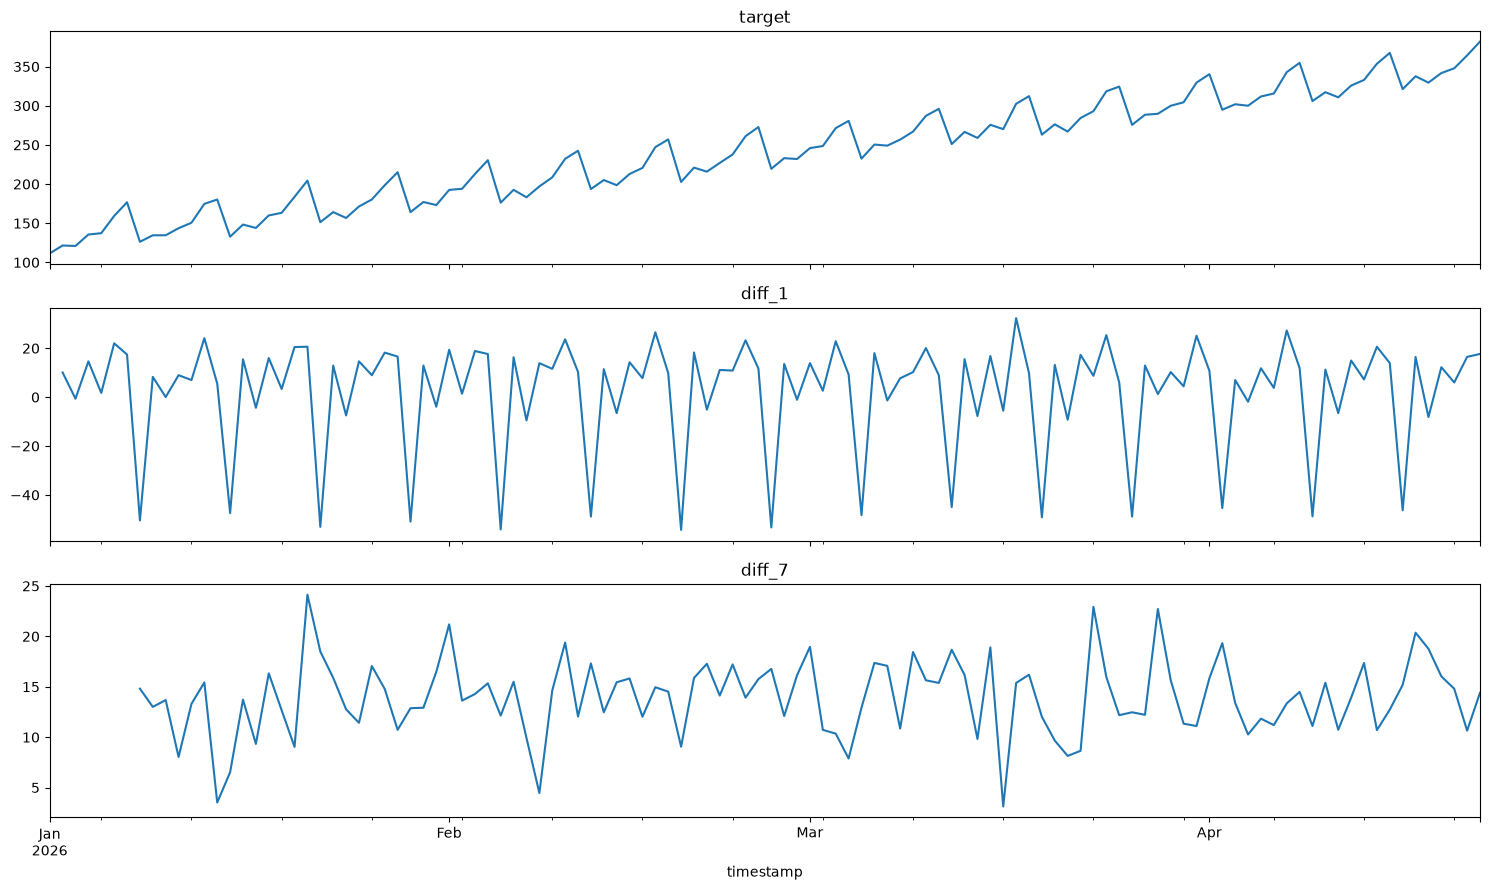

In [34]:
# Что остаётся в приращениях: на train видно, на чём модель учится в каждом варианте
increments_df = pd.DataFrame({
    "target": train_ts[:, "synthetic", "target"],
    "diff_1": train_ts[:, "synthetic", "target"].diff(1),
    "diff_7": train_ts[:, "synthetic", "target"].diff(7),
})

fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
for ax, column in zip(axes, increments_df.columns):
    increments_df[column].plot(ax=ax, title=column)
plt.tight_layout()

increments_df[["diff_1", "diff_7"]].describe().round(1)

#### Выводы

**Что поменялось.** Без `DifferencingTransform` CatBoost отвечал на вопрос «сколько будет заказов во вторник». С ним он отвечает на вопрос «на сколько этот вторник больше прошлого вторника» (`period=7`) или «на сколько сегодня больше, чем вчера» (`period=1`). Это и есть приращение. Само число заказов `Pipeline` собирает потом сам, простым сложением: **прогноз = значение неделю (или день) назад + прогноз приращения**.

**Потолка больше нет.** Максимум прогноза у `diff_7` — 408.3, у `diff_1` — 427.9, оба выше потолка train (381.9). Модель по-прежнему прогнозирует только числа из знакомого диапазона, но теперь это приращения: «+14 за неделю» модель в train видела много раз. Рост за потолок даёт сложение: прошлый вторник + 14.

**Почему `diff_7` лучше всех CatBoost (SMAPE 0.94 против 1.95 у `diff_1` и 2.12 без приращений).** В нашем ряде тренд +2 в день и недельный узор. Вторник минус прошлый вторник = 7 дней × 2 = **14**: узор вычитается сам из себя и исчезает, тренд превращается в одно постоянное число. Так и вышло: `diff_7` в train в среднем 13.9 при разбросе всего 3.8. Модели нужно выучить, по сути, одно число. Тренд и недельная форма приходят в прогноз из факта прошлой недели.

**Почему `diff_1` хуже.** Сегодня минус вчера убирает тренд (остаётся +2), но не убирает узор: «среда − вторник» и «четверг − среда» совсем разные. Поэтому `diff_1` скачет от −54 до +32, и модели приходится учить всю недельную форму. К тому же уровень собирается цепочкой из 14 дневных шагов, и каждая ошибка шага остаётся в прогнозе до конца. Видно по ошибкам: в первую неделю теста в среднем 2.6 по модулю, во вторую — уже 12.1, и почти все ошибки в одну сторону (выше факта).

**Почему вторник 05-05 у `diff_7` всё равно −12.7.** Прогноз на день — это «тот же день неделю назад + приращение». Для первой недели теста «неделя назад» — это факт из train. А для второй недели — уже наш собственный прогноз первой недели: факта там ещё нет. Цепочка такая: 05-05 = прогноз 04-28 + приращение = факт 04-21 + приращение + приращение.
- В последний вторник train (04-21) случайно было мало заказов — примерно на 6 меньше «нормы». Этот провал скопировался в оба тестовых вторника.
- Оба раза модель дала приращение чуть меньше 14 (около 11 и 10), и недобор сложился.

Это не рекурсия внутри модели: CatBoost все 14 приращений прогнозирует сразу, по известным лагам. Рекурсия возникает при сборке уровня обратно. Поэтому у `diff_7` ошибки во вторую неделю больше, чем в первую: в среднем 5.3 по модулю против 1.9. У Prophet, где такой цепочки нет, ошибка от недели к неделе почти не растёт: 2.8 и 3.4.

**Итог.** CatBoost не умеет продолжать тренд, но если дать ему ряд, где тренда нет, — приращения, — то справляется почти как Prophet (0.94 против 0.84). Лучше всего работает `period`, равный сезонности ряда: тогда одним вычитанием убираются и тренд, и сезонность.

### Шаг 1.4. Ряд без тренда

Сгенерируй тот же ряд с `slope=0` и повтори CatBoost (без дифференцирования) и Prophet.

- Насколько теперь отличаются модели?
- Сформулируй, на каких рядах CatBoost без дополнительных трансформов безопасен, а на каких нет.

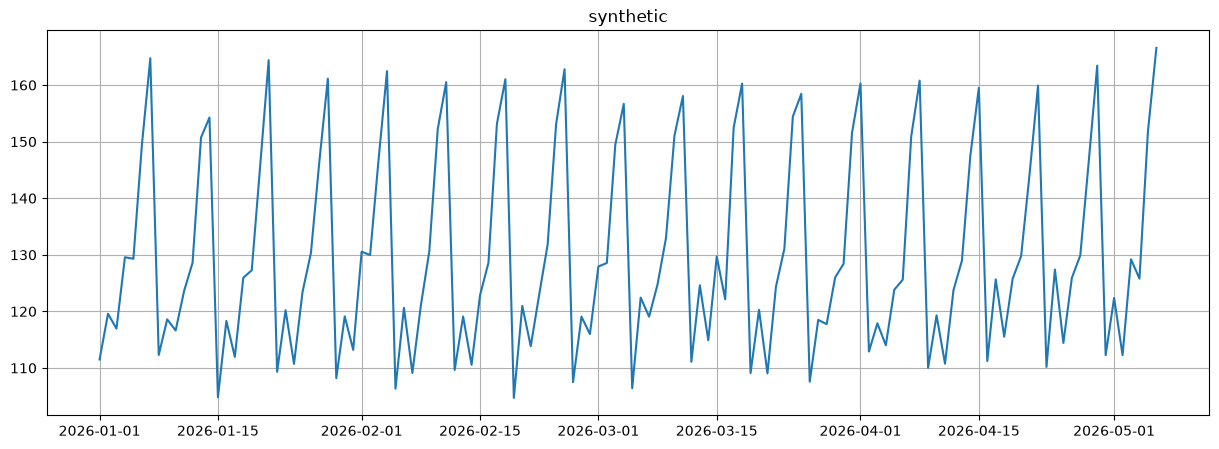

In [41]:
# Тот же ряд, но без тренда: только недельный узор + шум.
ts_flat = make_trend_series(slope=0)
ts_flat.plot(figsize=(15,5))

In [36]:
train_flat_ts, test_flat_ts = ts_flat.train_test_split(test_size=HORIZON)

flat_pipelines = {
    "catboost": Pipeline(
        CatBoostPerSegmentModel(random_seed=RANDOM_SEED),
        transforms=[LagTransform(in_column="target", lags=[14, 21, 28], out_column="lag")],
        horizon=HORIZON,
    ),
    "prophet": Pipeline(ProphetModel(), transforms=[], horizon=HORIZON),
    "catboost_diff_7": make_diff_pipeline(7),  # лучший вариант из шага 1.3 — нужен ли он без тренда?
}

forecasts_flat = {}
for name, pipeline in flat_pipelines.items():
    pipeline.fit(train_flat_ts)
    forecasts_flat[name] = pipeline.forecast()

errors_flat = pd.Series({
    name: SMAPE()(y_true=test_flat_ts, y_pred=forecast)["synthetic"]
    for name, forecast in forecasts_flat.items()
}, name="smape").round(2)
print(errors_flat)

catboost           2.35
prophet            2.26
catboost_diff_7    2.60
Name: smape, dtype: float64


train_max                       164.7
test_max                        166.6
catboost_forecast_max           160.2
prophet_forecast_max            160.0
catboost_diff_7_forecast_max    158.9
dtype: float64

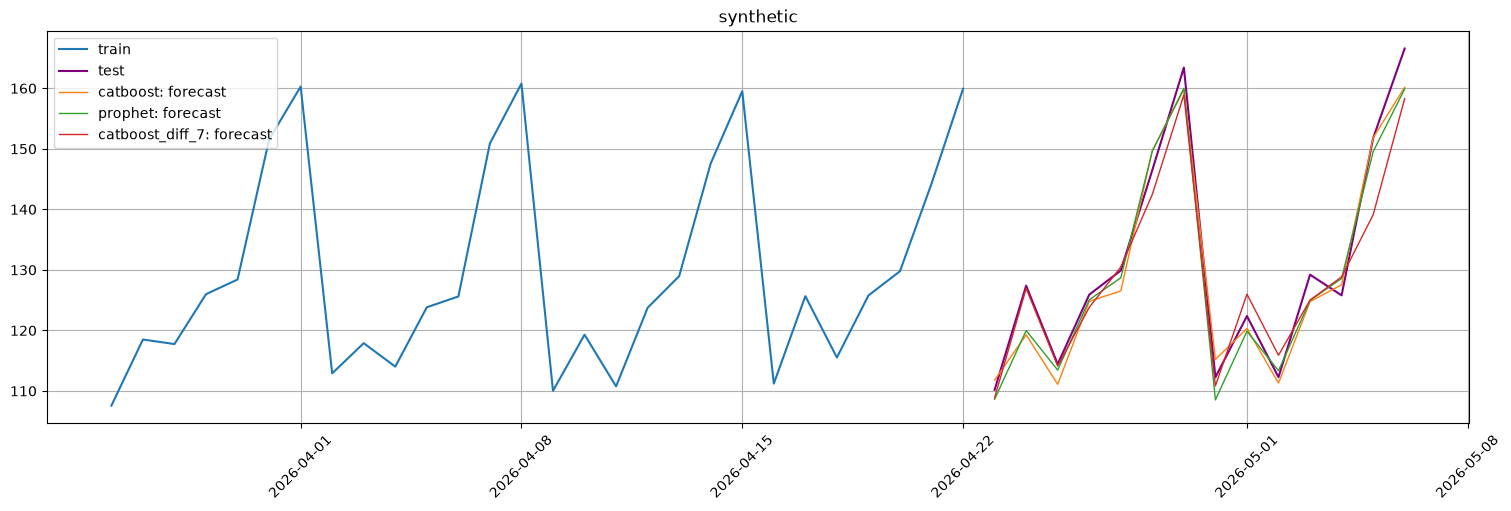

In [37]:
plot_forecast(forecast_ts=forecasts_flat, test_ts=test_flat_ts, train_ts=train_flat_ts, n_train_samples=28, figsize=(15, 5))

pd.Series({
    "train_max": train_flat_ts[:, "synthetic", "target"].max(),
    "test_max": test_flat_ts[:, "synthetic", "target"].max(),
    **{f"{name}_forecast_max": forecast[:, "synthetic", "target"].max() for name, forecast in forecasts_flat.items()},
}).round(1)

In [39]:
# Ошибка по дням теста: прогноз − факт
compare_flat_df = pd.DataFrame({
    "day_of_week": test_flat_ts.timestamps.day_name(),
    "fact": test_flat_ts[:, "synthetic", "target"],
}, index=test_flat_ts.timestamps)
for name, forecast in forecasts_flat.items():
    compare_flat_df[f"{name}_error"] = forecast[:, "synthetic", "target"] - compare_flat_df["fact"]

compare_flat_df.round(1)

,day_of_week,fact,catboost_error,prophet_error,catboost_diff_7_error
timestamp,,,,,
2026-04-23,Thursday,110.2,1.6,-1.6,-1.3
2026-04-24,Friday,127.4,-8.1,-7.4,-0.4
2026-04-25,Saturday,114.4,-3.3,-1.0,-0.3
2026-04-26,Sunday,125.9,-1.1,-0.8,-2.1
2026-04-27,Monday,129.9,-3.4,-1.2,0.6
2026-04-28,Tuesday,146.5,3.2,3.1,-4.0
2026-04-29,Wednesday,163.4,-3.7,-3.4,-4.5
2026-04-30,Thursday,112.3,2.9,-3.7,-1.4
2026-05-01,Friday,122.4,-2.1,-2.5,3.6


#### Выводы

| модель | SMAPE с трендом (шаг 1.2–1.3) | SMAPE без тренда |
|---|---|---|
| `catboost` | 2.12 | **2.35** |
| `prophet` | 0.84 | **2.26** |
| `catboost_diff_7` | 0.94 | **2.60** |

**Без тренда CatBoost и Prophet ошибаются почти одинаково — и почти идеально.**
- Ошибки совпадают день в день: самые большие у обоих 04-24 (−8.1 и −7.4) и 05-06 (−6.4 и −6.7). Это не промах моделей, а шум: в эти дни факт случайно выше нормы (узора) на +7.4 и +6.6. Такое не предскажет никто.
- Проверка: модель, которая знает настоящий узор **точно**, получила бы на этом тесте SMAPE 2.15. У CatBoost 2.35, у Prophet 2.26 — обе почти упёрлись в этот предел. Всё, что можно выучить из ряда, они выучили.
- Потолок CatBoost здесь не мешает: тест лежит внутри диапазона train (кроме выброса 05-06 = 166.6, но его не угадал и Prophet: оба дают ~160).
- Почему SMAPE без тренда выше, чем у Prophet с трендом (2.26 против 0.84)? Шум тот же (±3 заказа), а уровень ряда в 3 раза ниже (~130 против ~360). SMAPE — ошибка в процентах, поэтому та же ошибка в заказах даёт больший процент.

**Дифференцирование без тренда — лишнее.**
- `catboost_diff_7` здесь худший (2.60), и его ошибки **до десятых совпадают с шагом 1.3**: −1.3, −0.4, …, −12.7, −8.3. Без тренда приращения за неделю те же, только меньше ровно на 14, поэтому модель выучила то же самое.
- Значит, и слабое место то же: прогноз = «тот же день неделю назад + приращение». Опора — один конкретный прошлый день со своим шумом, а во вторую неделю — собственный прогноз. Отсюда снова −12.7 во вторник 05-05, хотя CatBoost и Prophet в этот день почти не ошиблись (0.1 и −2.2).
- Модели без дифференцирования опираются на несколько недель сразу (лаги 14, 21, 28 у CatBoost, вся история у Prophet), и шум одного дня у них усредняется.

**Итог: когда CatBoost безопасен.**
- **Безопасен** — когда будущие значения лежат в том же диапазоне, что train: ряд колеблется вокруг постоянного уровня. Тогда CatBoost на лагах не уступает Prophet.
- **Опасен** — когда ряд уходит за пределы train: тренд, рост, сдвиг уровня вверх или вниз. Прогноз упрётся в потолок (шаг 1.2).
- **`DifferencingTransform` — лекарство от тренда, а не бесплатное улучшение.** Есть тренд — помогает сильно (шаг 1.3). Нет тренда — делает прогноз чуть хуже. Поэтому сначала смотрим на ряд, потом решаем.

## Задание 2. Какие признаки модель видит на самом деле

Разбираем трансформы из раздела 1.4 на ряде без тренда из шага 1.4: что лежит в таблице признаков на train и в будущем, что из этого попадает в модель и что ломается, если нарушить правило «лаг ≥ горизонта».

### Шаг 2.1. Таблица признаков: train и будущее

Раздели ряд на train / test и примени к train через `fit_transform` четыре трансформа:
- `LagTransform(in_column="target", lags=[1, 7, 14], out_column="lag")`;
- `MeanTransform(in_column="target", window=7, out_column="mean_target_7")` — как в пособии;
- `MeanTransform(in_column="lag_14", window=7, out_column="mean_lag14_7")` — по лагу;
- `DateFlagsTransform(day_number_in_week=True, day_number_in_month=False, is_weekend=False, out_column="flag")`.

Посмотри первые ~20 строк train и таблицу будущего: `train_ts.make_future(future_steps=HORIZON, transforms=...)`. Выведи `train_ts.regressors`.

- В каких колонках будущего есть `NaN` или нули и с какого дня?
- Какие колонки ETNA считает регрессорами, а какие нет?

In [47]:
# Признаки строим на копии train ряда без тренда из шага 1.4 — сам train_flat_ts не трогаем
from copy import deepcopy


def make_feature_transforms() -> list:
    """Четыре трансформа шага 2.1. Функция создаёт их ЗАНОВО — пригодится в шаге 2.2."""
    return [
        LagTransform(in_column="target", lags=[1, 7, 14], out_column="lag"),
        MeanTransform(in_column="target", window=7, out_column="mean_target_7"),   # как в пособии: по target
        MeanTransform(in_column="lag_14", window=7, out_column="mean_lag14_7"),    # по лагу: среднее y[t-14] … y[t-20]
        DateFlagsTransform(day_number_in_week=True, day_number_in_month=False, is_weekend=False, out_column="flag"),
    ]


feature_transforms = make_feature_transforms()
features_train_ts = deepcopy(train_flat_ts)
features_train_ts.fit_transform(feature_transforms)

features_train_df = features_train_ts.to_pandas(flatten=True).drop(columns="segment").set_index("timestamp")
features_train_df.head(22).round(1)

,target,flag_day_number_in_week,lag_1,lag_14,lag_7,mean_lag14_7,mean_target_7
timestamp,,,,,,,
2026-01-01,111.5,3,NaN,NaN,NaN,0.0,111.5
2026-01-02,119.6,4,111.5,NaN,NaN,0.0,115.5
2026-01-03,116.9,5,119.6,NaN,NaN,0.0,116.0
2026-01-04,129.6,6,116.9,NaN,NaN,0.0,119.4
2026-01-05,129.3,0,129.6,NaN,NaN,0.0,121.4
2026-01-06,149.3,1,129.3,NaN,NaN,0.0,126.0
2026-01-07,164.7,2,149.3,NaN,NaN,0.0,131.6
2026-01-08,112.3,3,164.7,NaN,111.5,0.0,131.7
2026-01-09,118.6,4,112.3,NaN,119.6,0.0,131.5


In [45]:
# Будущее: те же трансформы, target пустой — модель увидит ровно эти признаки
features_future_df = (
    features_train_ts.make_future(future_steps=HORIZON, transforms=feature_transforms)
    .to_pandas(flatten=True)
    .drop(columns="segment")
    .set_index("timestamp")
)

features_future_df.round(1)

,target,flag_day_number_in_week,lag_1,lag_14,lag_7,mean_lag14_7,mean_target_7
timestamp,,,,,,,
2026-04-23,NaN,3,159.9,110.0,111.2,129.0,133.5
2026-04-24,NaN,4,NaN,119.3,125.7,129.2,135.0
2026-04-25,NaN,5,NaN,110.8,115.5,128.7,139.9
2026-04-26,NaN,6,NaN,123.7,125.8,128.7,144.6
2026-04-27,NaN,0,NaN,129.0,129.8,129.2,152.1
2026-04-28,NaN,1,NaN,147.6,144.2,128.7,159.9
2026-04-29,NaN,2,NaN,159.5,159.9,128.6,0.0
2026-04-30,NaN,3,NaN,111.2,NaN,128.7,0.0
2026-05-01,NaN,4,NaN,125.7,NaN,129.6,0.0


In [46]:
# Сводка по колонкам: регрессор ли (известна ли в будущем) и сколько пропусков / нулей в train и в будущем
feature_columns = [column for column in features_future_df.columns if column != "target"]
features_summary_df = pd.DataFrame({
    "is_regressor": [column in features_train_ts.regressors for column in feature_columns],
    "train_nan": features_train_df[feature_columns].isna().sum(),
    "future_nan": features_future_df[feature_columns].isna().sum(),
    # нули считаем только в числовых колонках: у flag_day_number_in_week 0 — это понедельник
    "future_zero": (features_future_df[feature_columns].select_dtypes("number") == 0).sum(),
}, index=feature_columns)

print("regressors:", features_train_ts.regressors)
features_summary_df

regressors: ['lag_1', 'lag_14', 'lag_7', 'mean_lag14_7', 'flag_day_number_in_week']


,is_regressor,train_nan,future_nan,future_zero
flag_day_number_in_week,True,0,0,NaN
lag_1,True,1,13,0.0
lag_14,True,14,0,0.0
lag_7,True,7,7,0.0
mean_lag14_7,True,0,0,0.0
mean_target_7,False,0,0,8.0


#### Выводы

**Правило одно: лаг $k$ — это «значение $k$ дней назад». Дыра появляется там, где на $k$ дней назад данных нет.** Дыры бывают в двух местах:

| признак | дыра в начале train | дыра в будущем (14 дней теста) |
|---|---|---|
| `lag_1` | 1 строка | **13 из 14 дней** — известен только 1-й день |
| `lag_7` | 7 строк | **7 из 14 дней** — известны дни 1–7 |
| `lag_14` | 14 строк | **нет** — известны все 14 дней |
| `mean_lag14_7` | нет `NaN`, но 14 строк **нулей** | нет |
| `flag_day_number_in_week` | нет | нет — день недели известен всегда |
| `mean_target_7` | нет | **дни 7–14 — нули**, дни 1–6 — «съезжающее» среднее |

**Train: дыра — в начале истории.** У первого дня ряда нет «вчера», у первой недели нет «неделю назад». Строки с `NaN` модель выбросит перед обучением (раздел 1.3): с лагами до 14 обучение начнётся только с 15-й строки (2026-01-15). Чем длиннее лаг, тем больше истории теряем.

**Будущее: дыра — в конце горизонта.** Прогноз делаем 2026-04-22 (последний день train). Для 1-го дня теста «вчера» — это 04-22, факт есть. Для 2-го дня «вчера» — это 1-й день теста, а его факта ещё нет. Поэтому:
- `lag_1` известен только на 1 день вперёд, `lag_7` — на 7, `lag_14` — на все 14;
- **лаг без дыр в будущем — только лаг ≥ горизонта.** Отсюда правило «порядок лага не меньше `HORIZON`».

**Два тихих подвоха — не `NaN`, а ноль.**
- `mean_lag14_7` в первых 14 строках train — `0.0`, а не `NaN`: так работает `fillna=0` у `MeanTransform`. Это не «ноль заказов», а «посчитать нечем». Здесь не страшно — те же строки всё равно выброшены из-за `NaN` в `lag_14`, — но если оставить только среднее без лага, модель будет учиться на фальшивых нулях. Плюс строки 15–20: окно заполнено не целиком (`min_periods=1`) — в 01-15 «среднее за 7 дней» на деле одно значение (111.5).
- `mean_target_7` в будущем: в первые 6 дней окно захватывает всё меньше дней train (в 6-й день — только последний, 159.9), а с 7-го дня внутри окна не остаётся ничего, и подставляется `0.0`. Модели ни ошибки, ни `NaN` — просто бессмысленные числа.

**Регрессоры.** ETNA считает регрессорами все колонки, кроме `mean_target_7`: лаги, день недели и среднее по `lag_14`. `mean_target_7` построено по `target`, а у `target` нет будущего — поэтому не регрессор. Что это значит для модели — в шаге 2.2.

**Итог.** Признак годится для прогноза на весь горизонт, только если он смотрит в прошлое не меньше, чем на `HORIZON` дней: `lag_14`, `mean_lag14_7`. Или если он известен заранее: день недели. Остальное либо дырявое в будущем (`lag_1`, `lag_7`), либо вообще не попадёт в модель (`mean_target_7`).

### Шаг 2.2. Что попало в модель

Обучи `CatBoostPerSegmentModel(random_seed=RANDOM_SEED)` на преобразованном train из шага 2.1 и выведи `model.get_model()["synthetic"].feature_names_`.

- Где `mean_target_7`? Почему его нет (раздел 1.3)?
- Сравни в train значение `mean_target_7` в строке $t$ с `target` той же строки и предыдущих 6 строк. Что было бы, если бы модель этот признак взяла?

In [48]:
# Обучаем CatBoost на таблице признаков из шага 2.1 и смотрим, какие колонки он реально взял
model_features = CatBoostPerSegmentModel(random_seed=RANDOM_SEED)
model_features.fit(features_train_ts)

used_features = model_features.get_model()["synthetic"].feature_names_
all_columns = [column for column in features_train_df.columns if column != "target"]

print("колонки в таблице:  ", all_columns)
print("признаки в модели:  ", used_features)
print("выброшены моделью:  ", sorted(set(all_columns) - set(used_features)))

колонки в таблице:   ['flag_day_number_in_week', 'lag_1', 'lag_14', 'lag_7', 'mean_lag14_7', 'mean_target_7']
признаки в модели:   ['lag_1', 'lag_14', 'lag_7', 'mean_lag14_7', 'flag_day_number_in_week']
выброшены моделью:   ['mean_target_7']


In [49]:
# Утечка: из чего состоит mean_target_7 в строке t? Считаем два варианта среднего по target вручную
leak_df = features_train_df[["target", "mean_target_7"]].copy()
leak_df["mean_with_today"] = leak_df["target"].rolling(7, min_periods=1).mean()              # дни t-6 … t
leak_df["mean_without_today"] = leak_df["target"].shift(1).rolling(7, min_periods=1).mean()  # дни t-7 … t-1
leak_df.iloc[7:15].round(1)

,target,mean_target_7,mean_with_today,mean_without_today
timestamp,,,,
2026-01-08,112.3,131.7,131.7,131.6
2026-01-09,118.6,131.5,131.5,131.7
2026-01-10,116.6,131.5,131.5,131.5
2026-01-11,123.6,130.6,130.6,131.5
2026-01-12,128.6,130.5,130.5,130.6
2026-01-13,150.7,130.7,130.7,130.5
2026-01-14,154.3,129.2,129.2,130.7
2026-01-15,104.8,128.2,128.2,129.2


In [51]:
# Что было бы, если бы модель взяла mean_target_7: обучаем CatBoost напрямую, мимо ETNA, на тех же колонках
from catboost import CatBoostRegressor

leak_columns = ["lag_14", "flag_day_number_in_week", "mean_target_7"]
clean_columns = ["lag_14", "flag_day_number_in_week", "mean_lag14_7"]

train_rows = features_train_df.dropna(subset=["lag_14"])  # как ETNA: строки без lag_14 выбрасываем
test_fact = test_flat_ts[:, "synthetic", "target"]

leak_rows = []
for name, columns in {"with_mean_target_7": leak_columns, "with_mean_lag14_7": clean_columns}.items():
    regressor = CatBoostRegressor(random_seed=RANDOM_SEED, logging_level="Silent", cat_features=["flag_day_number_in_week"])
    regressor.fit(train_rows[columns], train_rows["target"])
    train_pred = regressor.predict(train_rows[columns])
    test_pred = pd.Series(regressor.predict(features_future_df[columns]), index=features_future_df.index)
    leak_rows.append({
        "features": name,
        "train_mae": (train_pred - train_rows["target"]).abs().mean(),   # ошибка на тех строках, где училась
        "test_mae": (test_pred - test_fact).abs().mean(),                # ошибка на 14 днях теста
        "test_mae_days_1_6": (test_pred - test_fact).abs().iloc[:6].mean(),
        "test_mae_days_7_14": (test_pred - test_fact).abs().iloc[6:].mean(),
        "importance_of_mean": regressor.get_feature_importance(prettified=True).set_index("Feature Id").loc[columns[-1], "Importances"],
    })

pd.DataFrame(leak_rows).set_index("features").round(2)

,train_mae,test_mae,test_mae_days_1_6,test_mae_days_7_14,importance_of_mean
features,,,,,
with_mean_target_7,1.03,3.91,1.96,5.38,7.05
with_mean_lag14_7,1.22,3.71,3.64,3.77,4.94


#### Выводы

**В модель попали 5 признаков из 6.** `lag_1`, `lag_7`, `lag_14`, `mean_lag14_7`, день недели — да. `mean_target_7` — нет: ETNA выбросила его молча, без ошибки и без предупреждения. Причина из шага 2.1: это не регрессор (у `target` нет будущего), а CatBoost в ETNA берёт **только регрессоры**. Обрати внимание: `lag_1` и `lag_7` в модель попали, хотя в будущем они дырявые, — ETNA проверяет «есть ли будущее у колонки», а не «хватит ли его на весь горизонт».

**`mean_target_7` подглядывает в ответ.** Ручной пересчёт показывает, из чего он сделан:

| | окно | совпадает с `mean_target_7`? |
|---|---|---|
| `mean_with_today` | дни $t-6 \ldots t$ — **включая сегодня** | да, до десятых |
| `mean_without_today` | дни $t-7 \ldots t-1$ | нет |

То есть в строке за 14 января признак содержит заказы за 14 января — то самое число, которое модель должна предсказать. Это **утечка**: в train ответ лежит внутри признака, а в будущем его там нет.

**Что было бы, если бы модель его взяла.** Обучили CatBoost в обход ETNA на двух наборах (лаг 14 + день недели + одно из средних):

| признак-среднее | ошибка на train | ошибка на тесте | дни 1–6 | дни 7–14 |
|---|---|---|---|---|
| `mean_target_7` (с утечкой) | **1.03** | 3.91 | 1.96 | **5.38** |
| `mean_lag14_7` (честный) | 1.22 | **3.71** | 3.64 | 3.77 |

- **На train утечка выглядит лучше** (1.03 против 1.22): модель «знает» кусочек ответа. Так утечка и обманывает — на обучении всё хорошо.
- **На тесте — хуже** (3.91 против 3.71). Особенно в днях 7–14 (5.38 против 3.77): там окно уже целиком в будущем, и признак превращается в `0.0` (шаг 2.1). Модель такого значения в train не видела и прогнозирует наугад.
- Дни 1–6 у утечки случайно лучше (1.96): признак там считается по всё более короткому окну из последних дней train, и на 6 точках это совпадение, а не закономерность.
- Здесь эффект умеренный: сегодняшний день — лишь 1/7 окна. Чем короче окно, тем сильнее утечка: при `window=1` признак просто **равен** target, на train ошибка была бы ~0, а на тесте признак с 1-го дня — ноль.

**Итог.**
- ETNA защищает от этой ошибки сама: признак по `target` в модель не попадёт. Но молча — поэтому стоит проверять `feature_names_`.
- Скользящие статистики строим **по лагу ≥ горизонта** (`mean_lag14_7`), а не по `target`. Тогда окно всегда в прошлом, без утечки и без нулей в будущем.
- От дырявых лагов (`lag_1`, `lag_7`) ETNA **не** защищает — это следующий шаг 2.3.

### Шаг 2.3. Лаг меньше горизонта

Через `Pipeline` сравни три набора лагов на одном и том же ряде:
- `lags=[14, 21, 28]` — все лаги ≥ горизонта;
- `lags=[1, 7, 14]` — короткие лаги, свежая информация;
- `lags=list(range(1, 14))` — только лаги меньше горизонта.

- Какой набор лучше по SMAPE? Ожидал ли ты такого результата, учитывая, что у наборов с короткими лагами в train больше свежей информации?
- Посмотри важности признаков: какой лаг модель считала главным на train и в какие дни теста он у неё вообще есть?
- Выдала ли ETNA ошибку или предупреждение? Что CatBoost делает с `NaN` в будущих строках (раздел 1.3)?

lags_14_21_28    2.35
lags_1_7_14      7.59
lags_1_to_13     7.48
Name: smape, dtype: float64


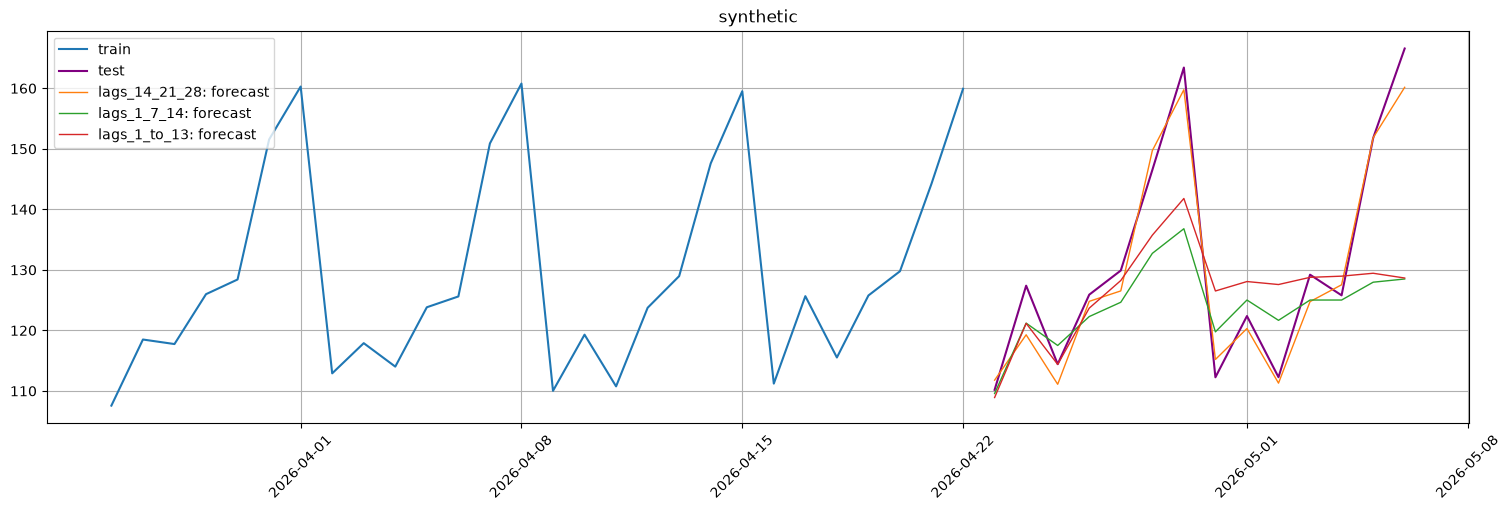

In [52]:
# Три набора лагов на ряде без тренда из шага 1.4: модель и всё остальное одинаковое, меняются только лаги
lag_sets = {
    "lags_14_21_28": [14, 21, 28],         # все лаги ≥ горизонта
    "lags_1_7_14": [1, 7, 14],             # свежая информация, но lag_1 и lag_7 дырявые в будущем
    "lags_1_to_13": list(range(1, 14)),    # только лаги меньше горизонта
}

lag_pipelines = {}
forecasts_lags = {}
for name, lags in lag_sets.items():
    lag_pipelines[name] = Pipeline(
        CatBoostPerSegmentModel(random_seed=RANDOM_SEED),
        transforms=[LagTransform(in_column="target", lags=lags, out_column="lag")],
        horizon=HORIZON,
    )
    lag_pipelines[name].fit(train_flat_ts)
    forecasts_lags[name] = lag_pipelines[name].forecast()

errors_lags = pd.Series({
    name: SMAPE()(y_true=test_flat_ts, y_pred=forecast)["synthetic"]
    for name, forecast in forecasts_lags.items()
}, name="smape").round(2)
print(errors_lags)

plot_forecast(forecast_ts=forecasts_lags, test_ts=test_flat_ts, train_ts=train_flat_ts, n_train_samples=28, figsize=(15, 5))

In [56]:
# Ошибка по дням теста + сколько признаков модели в этот день известны (не NaN)
features_known_df = pd.DataFrame(index=test_flat_ts.timestamps)
for name, lags in lag_sets.items():
    known_lags = pd.Series(range(1, HORIZON + 1), index=test_flat_ts.timestamps).apply(
        lambda day: sum(lag >= day for lag in lags)  # лаг k известен в день h теста, только если k ≥ h
    )
    features_known_df[f"{name}_known"] = known_lags.astype(str) + "/" + str(len(lags))

compare_lags_df = pd.DataFrame({
    "day": range(1, HORIZON + 1),
    "fact": test_flat_ts[:, "synthetic", "target"],
}, index=test_flat_ts.timestamps)
for name, forecast in forecasts_lags.items():
    compare_lags_df[f"{name}_error"] = forecast[:, "synthetic", "target"] - compare_lags_df["fact"]
compare_lags_df = compare_lags_df.join(features_known_df)

compare_lags_df.round(1)

,day,fact,lags_14_21_28_error,lags_1_7_14_error,lags_1_to_13_error,lags_14_21_28_known,lags_1_7_14_known,lags_1_to_13_known
timestamp,,,,,,,,
2026-04-23,1,110.2,1.6,-0.6,-1.3,3/3,3/3,13/13
2026-04-24,2,127.4,-8.1,-6.2,-6.2,3/3,2/3,12/13
2026-04-25,3,114.4,-3.3,3.1,-0.0,3/3,2/3,11/13
2026-04-26,4,125.9,-1.1,-3.6,-2.2,3/3,2/3,10/13
2026-04-27,5,129.9,-3.4,-5.2,-1.7,3/3,2/3,9/13
2026-04-28,6,146.5,3.2,-13.8,-10.8,3/3,2/3,8/13
2026-04-29,7,163.4,-3.7,-26.6,-21.6,3/3,2/3,7/13
2026-04-30,8,112.3,2.9,7.5,14.3,3/3,1/3,6/13
2026-05-01,9,122.4,-2.1,2.6,5.7,3/3,1/3,5/13


In [57]:
# Какой признак модель считала главным на train — и известен ли он ей в будущем (см. *_known в таблице выше)
importance_lags_df = pd.DataFrame({
    name: pipeline.model.get_model()["synthetic"].get_feature_importance(prettified=True).set_index("Feature Id")["Importances"]
    for name, pipeline in lag_pipelines.items()
})
importance_lags_df = importance_lags_df.sort_index(key=lambda index: index.str.removeprefix("lag_").astype(int))  # lag_1, lag_2, …
importance_lags_df.round(1)

,lags_14_21_28,lags_1_7_14,lags_1_to_13
Feature Id,,,
lag_1,NaN,16.4,3.5
lag_2,NaN,NaN,1.8
lag_3,NaN,NaN,3.1
lag_4,NaN,NaN,9.4
lag_5,NaN,NaN,2.4
lag_6,NaN,NaN,3.8
lag_7,NaN,37.7,58.9
lag_8,NaN,NaN,1.8
lag_9,NaN,NaN,2.5


#### Выводы

| набор лагов | SMAPE | главный признак на train (важность) | когда он есть в тесте |
|---|---|---|---|
| `14, 21, 28` | **2.35** | `lag_14` (39), `lag_28` (38) | все 14 дней |
| `1, 7, 14` | 7.59 | `lag_14` (46), `lag_7` (38) | `lag_7` — только дни 1–7 |
| `1 … 13` | 7.48 | `lag_7` (59) | только дни 1–7 |

**Короткие лаги — в 3 раза хуже.** И это при том, что «на бумаге» у них больше свежей информации.

**Почему: модель учили с признаками, а прогнозировать заставили без них.**
- На train у модели с короткими лагами все признаки есть всегда, и главный из них — `lag_7` (38 и 59 из 100): ряд недельный, «тот же день неделю назад» говорит о сегодняшнем дне больше всего.
- В тесте `lag_7` есть только первые 7 дней, `lag_1` — только 1-й день. Колонки `*_known` показывают, как признаки пропадают: у `1 … 13` к последнему дню не остаётся **ни одного** (0/13).
- Прогноз 05-06 у `1 … 13` построен вообще без признаков — и ошибка −37.9, самая большая в таблице.

**Как это видно по дням.**
- **Дни 1–5** — короткие лаги ошибаются примерно как длинные. Почти все признаки ещё на месте.
- **Пики (вторник и среда) — главные провалы:** −13.8 и −26.6 в первую неделю, −23.8 и −38.1 во вторую. Пустой признак CatBoost читает как «значение меньше любого из train» (раздел 1.3), то есть как «неделю назад был провал». Модель прогнозирует низко там, где на самом деле пик.
- **Спокойные дни во второй неделе — наоборот, перелёт** (четверг и суббота: от +7 до +15): без `lag_7` модель не может отличить, какой это день недели, и выдаёт «что-то среднее».
- У `14, 21, 28` ошибки ровные всю дорогу (от −8 до +3): все признаки на месте каждый день.

**Свежий `lag_1` тут вообще не помог.** Даже в 1-й день, когда он известен, выигрыша нет (−0.6 против 1.6 — в пределах шума). В синтетике шум каждого дня независимый: «вчера было больше нормы» ничего не говорит о завтра. На реальных данных вчерашний день может быть полезнее — но использовать его с прямой стратегией всё равно нельзя.

**ETNA и CatBoost не предупредили ни о чём.** Ни ошибки, ни предупреждения: `lag_1` — регрессор (шаг 2.2), а `NaN` CatBoost принимает молча. Модель тихо выдаёт плохой прогноз.

**Итог.**
- **Правило: порядок лага ≥ горизонта.** При `HORIZON = 14` — лаги от 14 и дальше. Проверка простая: у каждого признака в таблице будущего (шаг 2.1) не должно быть `NaN`.
- Хочешь использовать вчерашний день — нужен другой подход: `AutoRegressivePipeline` прогнозирует по одному дню и подставляет свои прогнозы в лаги (рекурсия, как у `SARIMAXModel`).

### Шаг 2.4. Важность признаков и SHAP-компоненты

Обучи конвейер с лагами `list(range(14, 29))` (все лаги с 14-го по 28-й).

1. Выведи важности `pipeline.model.get_model()["synthetic"].get_feature_importance(prettified=True)`.
2. Построй `plot_feature_relevance` с `ModelRelevanceTable()` и `RandomForestRegressor` (на `train_ts` после `fit_transform` с теми же лагами).
3. Получи прогноз с `return_components=True` и проверь, что компоненты в сумме дают прогноз.

- Какие лаги важнее всего и почему именно они (подумай про период паттерна)?
- Совпадают ли топы CatBoost и случайного леса?
- Чем компоненты CatBoost по смыслу отличаются от компонент `ProphetModel` (тренд + недельная волна)?

In [58]:
# Конвейер со всеми лагами с 14-го по 28-й: какие из них модель сочтёт важными?
importance_lags = list(range(14, 29))
importance_pipeline = Pipeline(
    CatBoostPerSegmentModel(random_seed=RANDOM_SEED),
    transforms=[LagTransform(in_column="target", lags=importance_lags, out_column="lag")],
    horizon=HORIZON,
)
importance_pipeline.fit(train_flat_ts)

# Важность в CatBoost (PredictionValuesChange): сколько в среднем меняется прогноз из-за признака, в сумме 100
catboost_importance = (
    importance_pipeline.model.get_model()["synthetic"]
    .get_feature_importance(prettified=True)
    .set_index("Feature Id")["Importances"]
)
catboost_importance.round(1)

Feature Id
lag_28    20.7
lag_21    18.5
lag_14    14.8
lag_25    10.1
lag_19     4.6
lag_17     4.2
lag_23     4.2
lag_24     3.5
lag_27     3.4
lag_26     3.1
lag_22     3.0
lag_18     2.9
lag_15     2.8
lag_20     2.4
lag_16     1.9
Name: Importances, dtype: float64

/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/etna/analysis/feature_relevance/relevance_table.py:33: UserWarning: Exogenous or target data contains None! It will be dropped for calculating relevance.
  warnings.warn("Exogenous or target data contains None! It will be dropped for calculating relevance.")


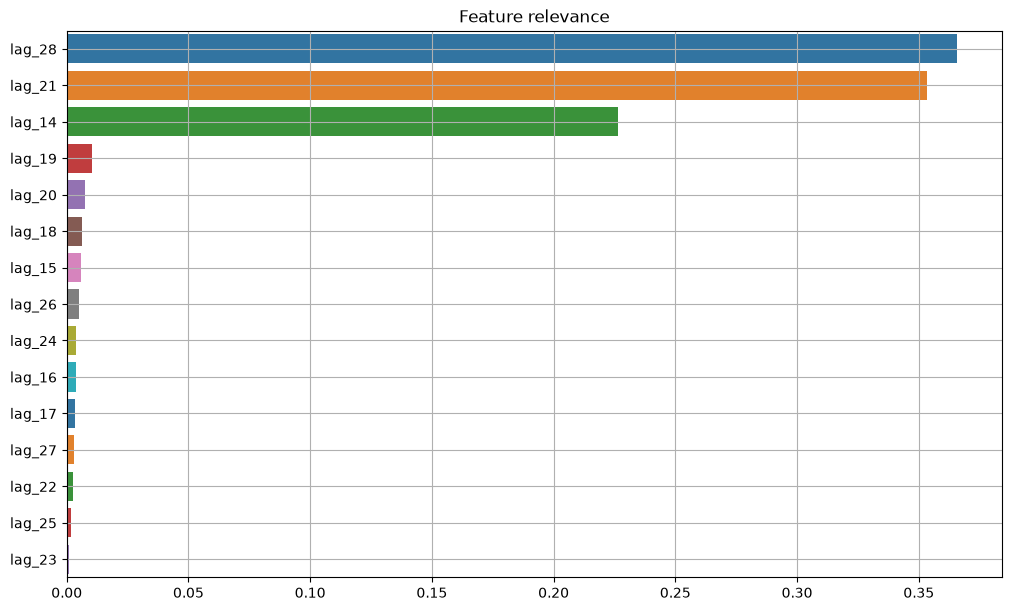

In [60]:
# Те же лаги — но важности по отдельной модели, случайному лесу (как в пособии)
importance_train_ts = deepcopy(train_flat_ts)
importance_transforms = [LagTransform(in_column="target", lags=importance_lags, out_column="lag")]
importance_train_ts.fit_transform(importance_transforms)

plot_feature_relevance(
    ts=importance_train_ts,
    relevance_table=ModelRelevanceTable(),
    normalized=True,  # в сумме 1
    relevance_params=dict(model=RandomForestRegressor(n_estimators=100, random_state=RANDOM_SEED)),
    figsize=(10, 6),
)

In [61]:
# Сравниваем топы: те же важности леса числами (ModelRelevanceTable сама выбрасывает строки с NaN)
importance_train_df = importance_train_ts.to_pandas(flatten=True).dropna()
lag_columns = [f"lag_{lag}" for lag in importance_lags]
forest = RandomForestRegressor(n_estimators=100, random_state=RANDOM_SEED).fit(importance_train_df[lag_columns], importance_train_df["target"])

importance_compare_df = pd.DataFrame({
    "lag_days_ago": importance_lags,
    "same_weekday": [lag % 7 == 0 for lag in importance_lags],  # лаг кратен 7 — тот же день недели
    "catboost": catboost_importance.reindex(lag_columns).values,
    "random_forest": forest.feature_importances_ * 100,         # тоже в сумме 100
}, index=lag_columns)
importance_compare_df["catboost_rank"] = importance_compare_df["catboost"].rank(ascending=False).astype(int)
importance_compare_df["random_forest_rank"] = importance_compare_df["random_forest"].rank(ascending=False).astype(int)
importance_compare_df.sort_values("catboost", ascending=False).round(1)

,lag_days_ago,same_weekday,catboost,random_forest,catboost_rank,random_forest_rank
lag_28,28,True,20.7,36.6,1,1
lag_21,21,True,18.5,35.3,2,2
lag_14,14,True,14.8,22.7,3,3
lag_25,25,False,10.1,0.2,4,14
lag_19,19,False,4.6,1.0,5,4
lag_17,17,False,4.2,0.3,6,11
lag_23,23,False,4.2,0.1,7,15
lag_24,24,False,3.5,0.4,8,9
lag_27,27,False,3.4,0.3,9,12
lag_26,26,False,3.1,0.5,10,8


In [63]:
# SHAP-компоненты: прогноз раскладывается на вклады признаков
forecast_components_ts = importance_pipeline.forecast(return_components=True)
components_df = forecast_components_ts.get_target_components()["synthetic"]
components_df.columns = components_df.columns.str.removeprefix("target_component_")

# Проверка: сумма вкладов = прогноз
forecast_y = forecast_components_ts[:, "synthetic", "target"]
print(f"максимальное расхождение суммы компонент и прогноза: {(forecast_y - components_df.sum(axis=1)).abs().max():.2e}")

# Подвох: ETNA делит базовое значение модели (средний прогноз) поровну между всеми признаками
# (etna/models/catboost.py, predict_components). Достаём базу из самого CatBoost, чтобы отделить её от вкладов
from catboost import Pool

future_features_df = importance_train_ts.make_future(future_steps=HORIZON, transforms=importance_transforms).to_pandas(flatten=True)
shap_values = importance_pipeline.model.get_model()["synthetic"].get_feature_importance(
    Pool(future_features_df[lag_columns]), type="ShapValues"
)
base_value = shap_values[0, -1]  # последний столбец — база, одинаковая для всех строк
pure_shap_df = components_df[lag_columns] - base_value / len(lag_columns)  # чистые вклады признаков

print(f"база модели: {base_value:.1f}, на каждый из {len(lag_columns)} лагов ETNA добавила по {base_value / len(lag_columns):.1f}")
components_df.iloc[:3].round(1)

максимальное расхождение суммы компонент и прогноза: 5.68e-14
база модели: 129.7, на каждый из 15 лагов ETNA добавила по 8.6


feature,lag_14,lag_15,lag_16,lag_17,lag_18,lag_19,lag_20,lag_21,lag_22,lag_23,lag_24,lag_25,lag_26,lag_27,lag_28
timestamp,,,,,,,,,,,,,,,
2026-04-23,3.9,8.0,8.6,8.2,7.9,8.5,8.1,5.4,7.8,8.1,7.9,7.2,8.5,7.7,3.2
2026-04-24,6.9,8.2,8.9,7.8,8.2,8.7,8.4,6.5,8.4,8.8,7.8,7.8,8.4,8.0,5.9
2026-04-25,5.8,8.3,8.5,6.7,7.9,8.4,8.1,6.3,8.2,8.2,8.0,7.3,8.1,7.8,6.3


In [64]:
# Первая неделя теста: прогноз = база + вклад лагов того же дня недели + вклад остальных лагов
weekday_lags = [f"lag_{lag}" for lag in importance_lags if lag % 7 == 0]   # lag_14, lag_21, lag_28
other_lags = [f"lag_{lag}" for lag in importance_lags if lag % 7 != 0]     # остальные 12

shap_week_df = pd.DataFrame({
    "day_of_week": components_df.index.day_name(),
    "base": base_value,
    "same_weekday_lags": pure_shap_df[weekday_lags].sum(axis=1),
    "other_lags": pure_shap_df[other_lags].sum(axis=1),
    "forecast": forecast_y,
}).iloc[:7]
shap_week_df.round(1)

,day_of_week,base,same_weekday_lags,other_lags,forecast
timestamp,,,,,
2026-04-23,Thursday,129.7,-13.5,-7.1,109.1
2026-04-24,Friday,129.7,-6.6,-4.3,118.7
2026-04-25,Saturday,129.7,-7.6,-8.4,113.8
2026-04-26,Sunday,129.7,-3.9,-1.8,123.9
2026-04-27,Monday,129.7,-3.4,2.1,128.5
2026-04-28,Tuesday,129.7,10.6,8.0,148.3
2026-04-29,Wednesday,129.7,15.7,14.2,159.6


#### Выводы

> Важности CatBoost немного меняются от запуска к запуску (порядок соседних лагов может поменяться), поэтому ниже — то, что устойчиво, а числа — приблизительные.

**Важны лаги «тот же день недели».** Из 15 лагов (14…28) в топ-3 у обеих моделей — `lag_14`, `lag_21`, `lag_28`: ровно 2, 3 и 4 недели назад. Ряд недельный, и «что было в этот же день недели» говорит о сегодняшнем дне больше всего. Остальные 12 лагов — это «соседние дни недели», у каждого всего несколько процентов.

**Случайный лес и CatBoost согласны в главном, но не в деталях.**

| | доля топ-3 (`lag_14/21/28`) | остальные 12 лагов |
|---|---|---|
| CatBoost | около 60–65% | по 2–5% каждый, порядок плавает |
| случайный лес | около 95% | почти ноль |

- Топ-3 совпадает, а порядок внутри него и хвост — нет. Хвост — это шум: лаги с важностью 2–5% меняются местами от модели к модели и от запуска к запуску. **Решать по ним, какой лаг выкинуть, нельзя** — только «сильные против слабых».
- Почему CatBoost размазывает важность шире: его деревья симметричные (раздел 1.2) — одно условие на весь уровень, и модель чаще берёт «второсортные» признаки. Плюс у моделей разные способы считать важность. Сравнивать можно ранги, но не сами числа.

**SHAP-компоненты: прогноз = база + вклады признаков.**
- Сумма компонент совпадает с прогнозом (расхождение ~1e-14) — как у `ProphetModel`, где прогноз был суммой тренда и недельной волны.
- **Подвох ETNA:** у модели есть **база** — средний прогноз, около 130 (среднее ряда без тренда: 100 + 30). ETNA делит её поровну между всеми 15 лагами — по ~8.6 каждому. Поэтому в сыром `get_target_components()` каждый лаг «весит» около 8, и ничего не понятно. Чистые вклады — это компонента минус 8.6.
- После вычитания картина понятная (первая неделя теста):

| день | база | лаги того же дня недели | остальные лаги | прогноз |
|---|---|---|---|---|
| четверг (самый слабый день) | ~130 | **около −14** | около −7 | ~110 |
| понедельник (средний) | ~130 | около −3 | около +2 | ~129 |
| среда (самый сильный) | ~130 | **около +16** | около +14 | ~160 |

  Модель стартует со среднего (130) и по лагам решает, какой это день: «2–4 недели назад в этот день было мало» → вниз, «было много» → вверх. Основной сдвиг дают `lag_14/21/28`. Остальные лаги тоже двигают в ту же сторону — они косвенно тоже знают день недели (например, `lag_15` в среду — это вторник две недели назад, тоже пиковый день).

**Чем это отличается от компонент `ProphetModel`.** У Prophet компоненты — это **части ряда**: тренд $g(t)$ и недельная волна $s(t)$, у каждой понятный смысл без модели. У CatBoost компоненты — это **ответ на вопрос «почему модель так решила»**: сколько каждый признак сдвинул прогноз от среднего. Отдельного «тренда» или «сезонности» тут нет — недельная форма размазана по лагам.

**Итог.** Важности и SHAP — инструмент, чтобы понять модель и отсеять явно бесполезные признаки. Но мелкие различия в них — шум, поэтому набор признаков всё равно выбираем по ошибке на отложенных данных (раздел 1.4, шаги 4.1 и 4.3).

## Задание 3. Загрузи данные по 2 юнитам размера `10+`

Те же 2 юнита и тот же период, что для предыдущих моделей, плюс длинная версия истории для шага 4.2.

### Шаг 3.1. Загрузка и сплит

1. Прочитай `facts-by-date.csv` и `units.csv`, оставь только 2 юнита размера `10+` (typical + busier).
2. Собери два `TSDataset` (дневная частота, `segment` = `MaskedUnitId`): стандартный — с 2026-04-01, и длинный — с 2025-01-01.
3. Раздели оба на train / test (последние `HORIZON` = 14 дней). Убедись, что test у них совпадает.

#### Выводы

### Шаг 3.2. Гипотеза до обучения

По тетрадям про `HoltWintersModel` и `ProphetModel` ты знаешь: тренда почти нет, недельная «пила» сильная, у `a6dffdeb` «пила» со временем сужается.

- Какие лаги подсказывает недельная сезонность при горизонте 14? Нужен ли `DifferencingTransform`?
- Посчитай: сколько строк train останется у модели после удаления строк с `NaN` при максимальном лаге 28, 56 и 364 — на стандартной и на длинной истории?
- Что может дать `DateFlagsTransform(day_number_in_week=True)` поверх лагов, кратных 7?

#### Выводы

## Задание 4. CatBoost на двух юнитах: признаки, история, гиперпараметры

Подбираем признаки и параметры CatBoost на данных из Задания 3 и проверяем выбор через backtest. Для ориентира — holdout macro SMAPE на тех же 2 юнитах и 14 днях: `HoltWintersModel(trend=None, seasonal="add")` — 7.77, лучший `SARIMAXModel` — 7.42, `ProphetModel()` — 9.09.

### Шаг 4.1. Наборы признаков

На стандартной истории обучи `Pipeline(CatBoostPerSegmentModel(random_seed=RANDOM_SEED), transforms, HORIZON)` с наборами:
- `flags_only` — только `DateFlagsTransform(day_number_in_week=True, day_number_in_month=False, is_weekend=False)`, без лагов;
- `lags_weekly` — лаги 14, 21, …, 56 (кратные 7);
- `lags_all` — все лаги с 14-го по 56-й;
- `lags_weekly_mean` — `lags_weekly` + `MeanTransform` по `lag_14` с окнами 7 и 28;
- `lags_weekly_flags` — `lags_weekly` + `DateFlagsTransform(day_number_in_week=True, day_number_in_month=False, is_weekend=False)`.

Сделай функцию `make_feature_sets()`, которая каждый раз создаёт **новые** трансформы, — пригодится в 4.2–4.4 и в бонусе.

Собери таблицу: строки — наборы, колонки — SMAPE по юнитам, SMAPE macro и bias по юнитам.

- Какой набор лучший? Подтвердилась ли гипотеза из шага 3.2?
- Насколько `flags_only` хуже наборов с лагами? Что это говорит о наших рядах (раздел 1.1, «А если без лагов»)?
- Где CatBoost оказался относительно `HoltWintersModel` и `ProphetModel`?

#### Выводы

### Шаг 4.2. Длина истории

Повтори 2 лучших набора из шага 4.1 на длинной истории (с 2025-01-01). Добавь ещё один вариант, невозможный на стандартной истории, — лучший набор + годовой лаг `364`.

Для каждого варианта выведи, на скольких строках модель реально училась.

- Помогла ли длинная история? Одинаково ли на обоих юнитах?
- Что дал годовой лаг?

#### Выводы

### Шаг 4.3. Гиперпараметры на валидационной выборке

Раздели train ещё раз: последние 14 дней train — **valid**, остальное — обучение. Test по-прежнему последние 14 дней ряда, на подборе его не трогаем.

С лучшим набором признаков переберь сетку `depth` ∈ {4, 6, 8} × `learning_rate` ∈ {0.03, 0.1} (`iterations=500`, `random_seed=RANDOM_SEED`): обучай на train без valid, считай SMAPE macro на valid. Потом для каждой комбинации посчитай и SMAPE на test (обучив на всём train) — только ради эксперимента, в жизни так не делают.

- Какая комбинация лучшая на valid, а какая на test? Совпали ли?
- Насколько разница между комбинациями больше или меньше разницы между valid и test одной и той же комбинации?

#### Выводы

### Шаг 4.4. Backtest: CatBoost против прошлых моделей

Прогони через `backtest` (`n_folds=5`, `mode="expand"`) на стандартной истории:
- 2–3 лучших варианта CatBoost из шагов 4.1–4.3;
- `ProphetModel(growth="flat")` — лучший Prophet по backtest;
- `HoltWintersModel(trend=None, seasonal="add", seasonal_periods=7)`.

Сравни holdout (последний фолд) и среднее по 5 фолдам, как в тетради про `ProphetModel`.

- Сохраняется ли порядок моделей?
- Выиграл ли CatBoost хоть один фолд? Что ему мешает на этих рядах — вспомни разделы 1.1 и 1.3?

#### Выводы

## Бонус. Все 10 юнитов: `PerSegment` против `MultiSegment` + логирование

Главное преимущество бустинга, которое на 2 юнитах не проявить, — одна модель на много рядов. Проверяем его на всех 10 юнитах и логируем в MLflow, чтобы CatBoost встал в одну таблицу с прошлыми моделями.

### Шаг Б.1. Все 10 юнитов: holdout и метрики

На стандартном периоде (с 2026-04-01, все 10 юнитов) с лучшим набором признаков из Задания 4 обучи:
- `CatBoostPerSegmentModel` — отдельная модель на юнит;
- `CatBoostMultiSegmentModel` — одна модель на все юниты;
- `CatBoostMultiSegmentModel` + `SegmentEncoderTransform()` — одна модель, которая знает, какой это юнит.

Посчитай весь набор метрик на holdout — `SMAPE`, `WAPE`, `MAPE`, `MAE`, `Bias` (через `src/prod_metrics.py`), per-segment и агрегированно (`smape_macro`, `mape_macro`, `mae_macro`, `wape_pooled`, `bias_pooled`, `fit_sec`) — те же имена, что у прошлых запусков.

- Помогает ли одна модель на все юниты? Что даёт `SegmentEncoderTransform`?

#### Выводы

### Шаг Б.2. Метрика по backtest

Для каждого варианта прогони `backtest` (`n_folds=5`, `mode="expand"`, `aggregate_metrics=True`) и добавь к агрегатам `smape_backtest_macro` — среднее SMAPE по юнитам и 5 фолдам, как в тетради про `ProphetModel`.

- Совпадает ли порядок вариантов на holdout и на backtest?

#### Выводы

### Шаг Б.3. Таблица по юнитам

Собери таблицу `result` по юнитам: `segment` / `unit_size` / `pick_reason` / `total_orders` + все метрики + SMAPE по backtest.

- На каких юнитах `MultiSegment` выигрывает у `PerSegment`, а на каких проигрывает? Есть ли связь с размером юнита?

#### Выводы

### Шаг Б.4. Логирование в MLflow

Залогируй каждый вариант отдельным запуском через `log_to_mlflow(...)`:
- имя запуска: `CatBoost_<вариант>_ch08_all_10_day`, например `CatBoost_per_segment_ch08_all_10_day`, `CatBoost_multi_segment_enc_ch08_all_10_day`;
- теги: `{"chapter": "ch08", "units_scope": "all_10", "granularity": "day", "model_family": "catboost", "approach": "one_config", "impl": "catboost"}` + теги варианта (`"segment_mode"`: `per_segment` / `multi_segment`, `"features"`: имя набора признаков);
- параметры: параметры модели, список лагов и прочих трансформов, `horizon`, `backtest_n_folds`, `backtest_mode`.

#### Выводы

### Шаг Б.5. Сравнение с прошлыми моделями

Сравни в MLflow (или через `mlflow.search_runs`, как в конце тетради про `ProphetModel`) лучший CatBoost с `Prophet_flat_ch07`, `HoltWinters_add_add_ch07` и другими запусками на 10 юнитах — по `smape_macro` и по `smape_backtest_macro`.

- Где CatBoost встаёт в общей таблице?
- На каких юнитах он лучший?

#### Выводы